# Baseline — Phase 2

## Context

Phase 1 (`data-viz.ipynb`) ends with one reference table per circuit, containing:

- a **tyre degradation slope**,
- a **pit-stop loss**,
- the **stint lengths** actually driven.

## Objective

This notebook builds the **baseline** that those numbers have to beat: a lap-time model that is **fitted on some races and scored on races it has never seen**.

The goal is that every later model is compared against a measured number, not against an impression.

## Data

The reference table is **not rebuilt here**. `f1data.build_base()` is the single place where it is built.

This notebook reads it exactly as section 9 of phase 1 does, with two additional columns that phase 1 asked for but did not have:

| Column       | Description                      |
|--------------|----------------------------------|
| `track_temp` | Track temperature during the lap |
| `traffic`    | Traffic context for the lap      |

## 1. Setup

In [1]:
# f1data is edited while this notebook is open: without autoreload, a function added to the
# module after the import below stays invisible until the kernel is restarted.
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import f1data
from f1data import COMPOUNDS

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid", context="notebook")

## 2. The analysis table

### Loading the data

`load_raw()` fetches every endpoint for 2023–2026 **once** and passes the resulting frames to `build_base()`. Calling it a second time would re-read the whole cache for nothing.

The `intervals` endpoint is included, since `traffic` is computed from it. It is also the heaviest endpoint: expect a few minutes on the first run, after which it is served from `app/data/cache`.

### Building the base table

`build_base()` keeps only the **clean laps of dry races, from lap 2 onward**, excluding neutralised laps.

It then attaches the following to each lap:

- compound
- tyre age
- circuit
- season
- weather
- traffic

In [2]:
raw = f1data.load_raw()          # with intervals, once
base = f1data.build_base(raw)

print()
print(f"base {len(base):,} laps, {base['session_key'].nunique()} races, "
      f"{base['circuit'].nunique()} circuits, {base['year'].nunique()} seasons")
print(f"track_temp on {base['track_temp'].notna().mean():.1%} of laps, "
      f"traffic on {base['traffic'].notna().mean():.1%}")

91 races held over 2023-2026
  laps          (98184, 16)
  stints        (36955, 8)
  pit           (31783, 8)
  weather       (50929, 10)
  race_control  (26261, 11)
  intervals     (2131795, 7)

base 73,343 laps, 77 races, 25 circuits, 4 seasons
track_temp on 100.0% of laps, traffic on 94.5%


## 3. The target

The model does not predict the lap time itself. A raw target of 70 to 105 s is dominated by the circuit, and an error on it is not comparable from Monza to Monte Carlo.

### Candidates

Five candidate targets, and what each one costs:

| Target | Gains | Costs |
|---|---|---|
| Raw lap time | Nothing to decide | 70–105 s: the circuit dominates, errors do not compare |
| Gap to the race median, all drivers | Simple, robust, in seconds | Still contains the driver and team level |
| Ratio to the fastest lap of the race | Unitless | The minimum is a single extreme lap, so it is noisy |
| Gap to the driver's own median | Removes the driver level | **Depends on that driver's strategy** |
| Gap to the median of the same lap across the field | Removes fuel, weather, restarts | Removes what we are trying to model |

### Decision

**Chosen: the gap to the median of the race, over all drivers, in seconds.**

This is the same normalisation that section 10 of phase 1 already draws its lap clouds against.

### Why not the alternatives

- **Not the driver's own median.** A one-stopper and a two-stopper do not run the same average tyre age, so their medians differ *because of the strategy*. The target would then move with the very decision the simulator exists to score. Using all twenty drivers absorbs this effect.
- **Not the median of the same lap across the field.** It removes the fuel effect and the track evolution, which are exactly what the model has to learn.
- **Not a ratio.** The pit-stop loss is in seconds, the degradation slope is in seconds per lap, and the simulator adds them together. Section 5 tests whether that scale holds up.

### What the target still contains, on purpose

- **The fuel effect.** The median falls mid-race, so the gap starts positive and ends negative. It is measured below, and it is the main check that the target is correctly built.
- **The driver and team level.** It exceeds 1 s and is probably the largest single source of variance. This is what a driver-level variable is for, later.
- **The tyre age, the compound and the weather.**

### What it removes, and the limit to state

The target removes the level of the race: the car of that season and the state of the track that day.

**Limit:** the median of a test race is information that would not be available before that race.

- For **ranking strategies**, this does not matter, because the constant is identical for every plan being compared.
- For **predicting an absolute lap time**, it is not a true forecast.

What this notebook produces is a comparison between models, not a lap-time prediction.

### Construction rules

1. **One function, computed once.** The reference is computed on the whole `base` table and stored in `ref_pace`. It is never recomputed on a subset: as measured below, redoing it on one moves the target by up to 1.2 s, more than the 0.703 s of RMSE that phase 1 left to beat.
2. **A race only sees its own laps**, so no reference can leak between training and validation.
3. **A quality threshold** is applied to the races, and the result is counted and printed.
4. **Median, not mean**, so the reference survives a slow lap that escaped the cleaning.

In [3]:
# One table from here on, and it carries the target: `gap` = lap time - median lap of its race.
# The reassignment is deliberate - a second table built from this one is a second target.
base, per_race = f1data.add_target(base)

kept = per_race[per_race["kept"]]
print(f"{len(kept)} races kept, {len(per_race) - len(kept)} excluded (thresholds: "
      f">= {f1data.TARGET_MIN_LAPS} clean laps and >= {f1data.TARGET_MIN_DRIVERS} drivers)")
print(f"{len(base):,} laps, {base['circuit'].nunique()} circuits, "
      f"{kept['year'].min()}-{kept['year'].max()}")
if (~per_race["kept"]).any():
    print()
    print("excluded:")
    print(per_race[~per_race["kept"]][["circuit", "year", "laps", "drivers"]].to_string())

print()
print("thinnest races kept - what the threshold guards against:")
print(kept.nsmallest(3, "laps")[["circuit", "year", "laps", "drivers", "ref_pace"]]
      .round(2).to_string())
print()
print("target `gap` (s):")
print(base["gap"].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(3).to_string())

77 races kept, 0 excluded (thresholds: >= 200 clean laps and >= 12 drivers)
73,343 laps, 25 circuits, 2023-2026

thinnest races kept - what the threshold guards against:
               circuit  year  laps  drivers  ref_pace
session_key                                          
10033            Miami  2025   409       19     91.25
7787         Melbourne  2023   590       19     82.20
9173            Suzuka  2023   668       19     98.58

target `gap` (s):
count    73343.000
mean         0.045
std          1.308
min         -5.521
1%          -2.767
25%         -0.847
50%          0.000
75%          0.876
99%          3.520
max          7.940


## 4. Is the target correctly built?

Three things have to hold, and one has to show up.

### Checks that must hold

`f1data.check_target()` raises on the three ways the target can be quietly wrong:

1. **A race whose median is not zero.** This means the reference was computed from laps other than that race's own.
2. **A missing value.**
3. **A race left without a reference.**

### Effect that must show up

The **fuel effect**: the mean gap must fall across the race, by roughly the 0.055 s/lap measured in phase 1. A flat curve would mean the reference is absorbing something it should not.

### Reading the plots

- **Left panel:** the distribution of the target per circuit, ordered by lap time.
  - Each box is centred on zero **by construction**.
  - The widths being comparable is **not** by construction. This is what section 5 examines.

{'races': 77, 'laps': 73343, 'max |median| per race': np.float64(7.105427357601002e-15), 'missing': 0}

fuel slope per race: median -0.0445 s/lap (q25 -0.0563, q75 -0.0332), negative in 77/77 races
mean gap +1.49 s over the first 5 % of the race, -0.85 s over the last


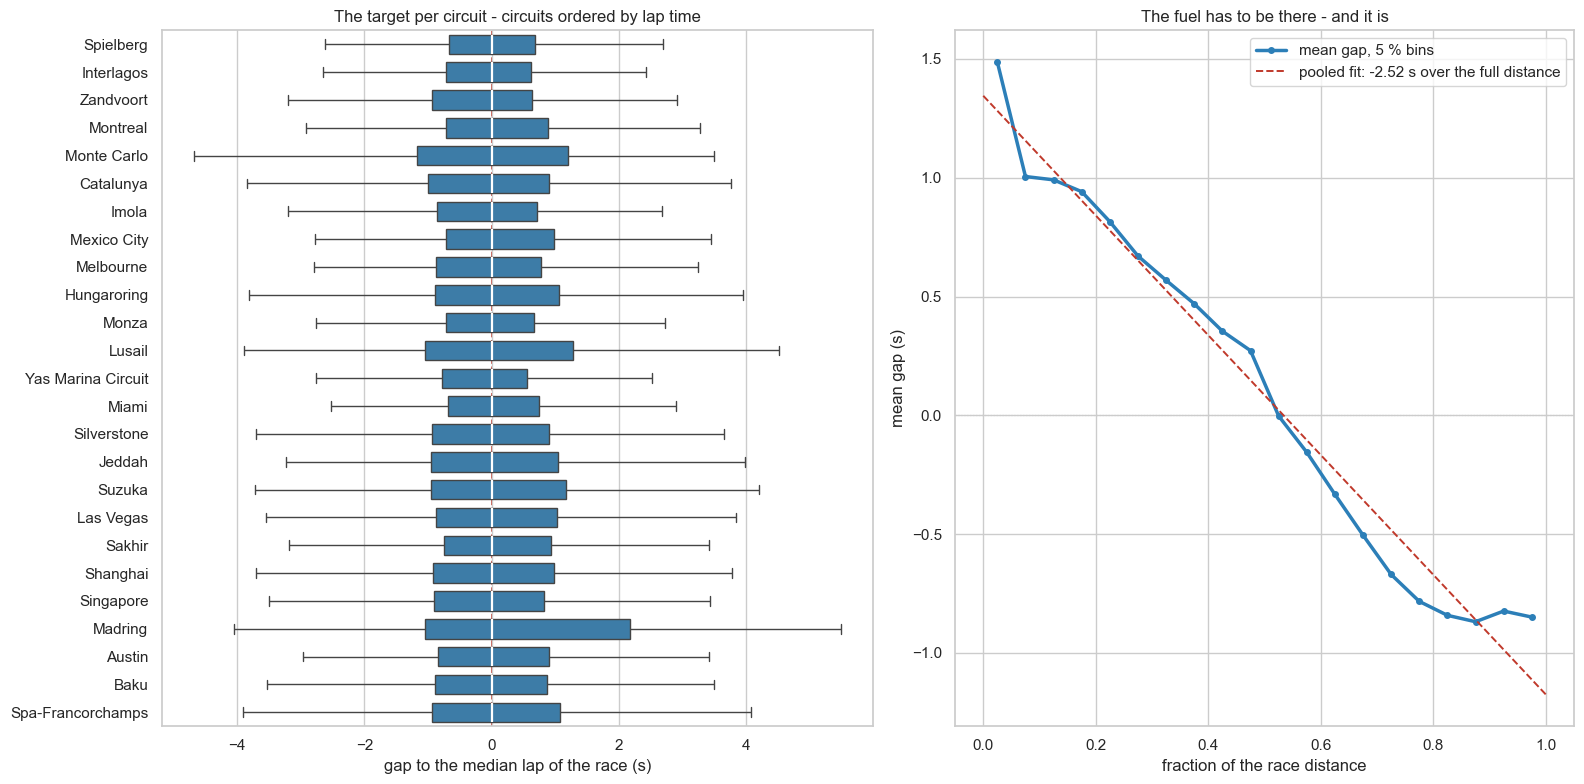

In [4]:
print(f1data.check_target(base))

# Where in the race each lap falls. The distance is the highest lap number of the race in the raw
# table, not in `base`: the cleaning removes laps, and the last lap is often one of them.
distance = raw.laps.groupby("session_key")["lap_number"].max()
base["race_frac"] = base["lap_number"] / base["session_key"].map(distance)

order = base.groupby("circuit")["lap_duration"].median().sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(16, 8), width_ratios=[1.15, 1])

# The median of each box is white and the zero line sits behind them: the two have to be
# read against each other, and a red line on top of the medians hides what it is checking.
sns.boxplot(data=base, x="gap", y="circuit", order=order, showfliers=False,
            color="#2c7fb8", width=0.7, ax=axes[0], medianprops=dict(color="white", lw=1.6))
axes[0].axvline(0, color="#c0392b", lw=1.2, ls="--", zorder=0)
axes[0].set(title="The target per circuit - circuits ordered by lap time",
            xlabel="gap to the median lap of the race (s)", ylabel="")

# The fuel signature: one slope per race, and the pooled curve over the race distance.
slope = base.groupby("session_key").apply(
    lambda x: np.polyfit(x["lap_number"], x["gap"], 1)[0], include_groups=False)
binned = base.groupby(pd.cut(base["race_frac"], np.arange(0, 1.001, 0.05)),
                      observed=True)["gap"].agg(["mean", "size"])
centres = [i.mid for i in binned.index]

axes[1].axhline(0, color="#9a9a9a", lw=0.8, ls=":", zorder=0)
axes[1].plot(centres, binned["mean"], color="#2c7fb8", lw=2.5, marker="o", ms=4,
             label="mean gap, 5 % bins")
fit = np.polyfit(base["race_frac"], base["gap"], 1)
axes[1].plot([0, 1], np.polyval(fit, [0, 1]), color="#c0392b", lw=1.4, ls="--",
             label=f"pooled fit: {fit[0]:+.2f} s over the full distance")
axes[1].set(title="The fuel has to be there - and it is",
            xlabel="fraction of the race distance", ylabel="mean gap (s)")
axes[1].legend(loc="upper right", frameon=True)

fig.tight_layout()

print()
print(f"fuel slope per race: median {slope.median():+.4f} s/lap "
      f"(q25 {slope.quantile(0.25):+.4f}, q75 {slope.quantile(0.75):+.4f}), "
      f"negative in {(slope < 0).sum()}/{len(slope)} races")
print(f"mean gap {binned['mean'].iloc[0]:+.2f} s over the first 5 % of the race, "
      f"{binned['mean'].iloc[-1]:+.2f} s over the last")

### The reference is never recomputed on a subset

Rule 1 is not a style preference. Below, the reference is recomputed on three subsets that a later cell could plausibly want:

- the laps whose traffic is known,
- the laps in clear air,
- the laps on tyres under 15 laps old.

Each one produces a **different target**, by enough to swamp the difference between two models.

In [5]:
for name, subset in [("traffic known", base[base["traffic"].notna()]),
                     ("clear air (traffic > 1 s)", base[base["traffic"] > 1]),
                     ("tyre age <= 15 laps", base[base["age"] <= 15])]:
    moved = (subset.groupby("session_key")["lap_duration"].median() - kept["ref_pace"]).dropna()
    print(f"{name:26s} ref_pace moves {moved.abs().mean():.3f} s on average, "
          f"up to {moved.abs().max():.3f} s   ({len(subset) / len(base):.0%} of the laps)")
print()
print("For scale: phase 1 left 0.703 s of RMSE per lap to beat.")

traffic known              ref_pace moves 0.076 s on average, up to 0.178 s   (94% of the laps)
clear air (traffic > 1 s)  ref_pace moves 0.135 s on average, up to 0.615 s   (72% of the laps)
tyre age <= 15 laps        ref_pace moves 0.235 s on average, up to 1.247 s   (60% of the laps)

For scale: phase 1 left 0.703 s of RMSE per lap to beat.


## 5. Sensitivity: seconds, or a relative scale?

The target is in seconds, across circuits whose laps run from 71 s to 111 s.

### The question

If the spread of the gap grew with the lap time, a circuit would collect a larger error for being **long** rather than for being **hard to model**. In that case the scale should be relative (a ratio, or a log).

### The test

Compare the spread per circuit against its lap time, in two ways:

1. **Absolute spread** (in seconds) vs lap time.
2. **Relative spread** (spread / lap time) vs lap time. This is the decisive half: is the relative spread any more stable than the spread in seconds?

### How to read the result

- If dispersion were proportional to lap time, dividing by it would **collapse the range**, and a relative scale would be justified.
- If the range does **not** collapse, the spread reflects **track character** rather than track length, and **seconds stay**.

spread in seconds : 0.94 to 2.10 s   (x2.25)
spread relative   : 1.13 to 2.11 %   (x1.87)
lap time          : 71.2 to 111.4 s   (x1.57)

corr(lap time, spread in s) = +0.46,  so lap length explains 21 % of the spread between circuits
corr(lap time, relative spread) = -0.20
on the 24 circuits with more than one race: spread in seconds spans x1.72, relative spans x1.82

Verdict: the link is real but weak, and the two widest circuits (Monte Carlo, Madring) are mid-length ones.
Dividing by the lap time does not tidy the range up - x1.87 against x2.25 over all circuits, and x1.82 against x1.72 once the
single-race ones are dropped, where it is worse - while turning the correlation negative, i.e. overcorrecting.
The target stays in seconds. Revisit this if a future circuit is both long and wide.

                      lap    sd  laps  n    cv
circuit                                       
Madring             99.63  2.10   993  1  2.11
Monte Carlo         78.39  1.61  3223  3  2.05
Spa-Franco

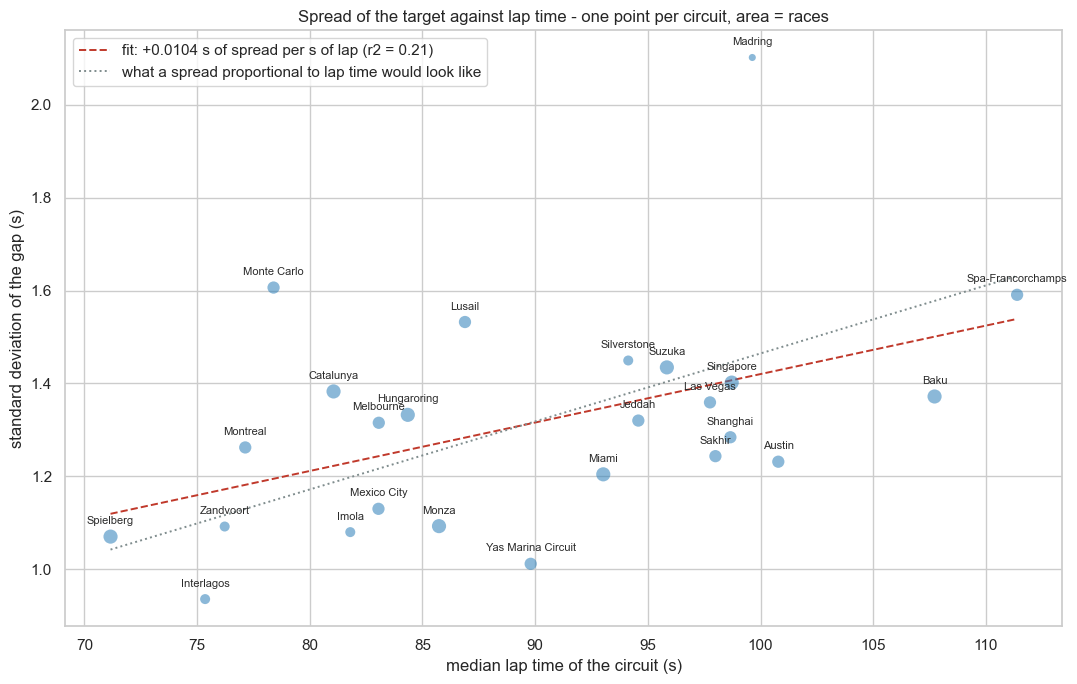

In [6]:
spread = base.groupby("circuit").agg(lap=("lap_duration", "median"), sd=("gap", "std"),
                                     laps=("gap", "size"), n=("session_key", "nunique"))
spread["cv"] = 100 * spread["sd"] / spread["lap"]      # relative spread, in % of a lap

fit_sd = np.polyfit(spread["lap"], spread["sd"], 1)
r_sd = np.corrcoef(spread["lap"], spread["sd"])[0, 1]
r_cv = np.corrcoef(spread["lap"], spread["cv"])[0, 1]
span = lambda s: s.max() / s.min()

fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(spread["lap"], spread["sd"], s=spread["n"] * 26, color="#2c7fb8",
           alpha=0.55, lw=0, zorder=2)
grid = np.array([spread["lap"].min(), spread["lap"].max()])
ax.plot(grid, np.polyval(fit_sd, grid), color="#c0392b", lw=1.4, ls="--", zorder=1,
        label=f"fit: {fit_sd[0]:+.4f} s of spread per s of lap (r2 = {r_sd ** 2:.2f})")
ax.plot(grid, spread["sd"].median() * grid / spread["lap"].median(), color="#7f8c8d", lw=1.4,
        ls=":", zorder=1, label="what a spread proportional to lap time would look like")
for c, row in spread.iterrows():
    ax.annotate(c, (row["lap"], row["sd"]), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=8, color="#2b2b2b")
ax.set(title="Spread of the target against lap time - one point per circuit, area = races",
       xlabel="median lap time of the circuit (s)", ylabel="standard deviation of the gap (s)")
ax.legend(loc="upper left", frameon=True)
fig.tight_layout()

print(f"spread in seconds : {spread['sd'].min():.2f} to {spread['sd'].max():.2f} s"
      f"   (x{span(spread['sd']):.2f})")
print(f"spread relative   : {spread['cv'].min():.2f} to {spread['cv'].max():.2f} %"
      f"   (x{span(spread['cv']):.2f})")
print(f"lap time          : {spread['lap'].min():.1f} to {spread['lap'].max():.1f} s"
      f"   (x{span(spread['lap']):.2f})")
print()
print(f"corr(lap time, spread in s) = {r_sd:+.2f},  so lap length explains "
      f"{100 * r_sd ** 2:.0f} % of the spread between circuits")
print(f"corr(lap time, relative spread) = {r_cv:+.2f}")

# Madring is one race of 993 laps and the widest circuit of the table: the verdict cannot be
# allowed to rest on it, so both ranges are recomputed without the single-race circuits.
solid = spread[spread["n"] >= 2]
print(f"on the {len(solid)} circuits with more than one race: spread in seconds spans "
      f"x{span(solid['sd']):.2f}, relative spans x{span(solid['cv']):.2f}")
print()
print(f"Verdict: the link is real but weak, and the two widest circuits (Monte Carlo, Madring) "
      f"are mid-length ones.")
print(f"Dividing by the lap time does not tidy the range up - x{span(spread['cv']):.2f} against "
      f"x{span(spread['sd']):.2f} over all circuits, and x{span(solid['cv']):.2f} against "
      f"x{span(solid['sd']):.2f} once the")
print(f"single-race ones are dropped, where it is worse - while turning the correlation negative, "
      f"i.e. overcorrecting.")
print("The target stays in seconds. Revisit this if a future circuit is both long and wide.")
print()
print(spread.sort_values("sd", ascending=False).head(4).round(2).to_string())